# Assignment 5: Advanced Modeling — Lung Cancer Survival Group

**Objective**: To test whether advanced ensemble models (Random Forest, Gradient Boosting, and tuned Random Forest) can improve upon the Assignment 4 baseline models (Logistic Regression, Decision Tree, KNN) in predicting Survival_Group. This assignment uses GridSearchCV for tuning, 5-fold cross-validation for consistency, and SHAP to explain the models' predictions. 

## 1. Imports 

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Machine Learning Imports
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)

from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
print("Imports successful.")

Imports successful.


## 2. Load Data & Preprocessing


In [9]:
DATA_PATH = "../data/cleaned_dataset_assignment3.csv"
df = pd.read_csv(DATA_PATH)

target = "Survival_Group"
y = df[target].copy()

redundant_raw_categories = ["Stage", "Treatment", "Gender", "Smoking_History"]
X = df.drop(columns=[target] + [c for c in redundant_raw_categories if c in df.columns]).copy()

cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = X.select_dtypes(include=np.number).columns.tolist()

# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# Preprocessing Pipeline
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, num_cols),
    ("categorical", categorical_pipeline, cat_cols)
])

print("Data loaded and preprocessed successfully.")

Data loaded and preprocessed successfully.


## 3. Train Random Forest (Advanced Model 1)
Random Forest is an ensemble method that builds multiple decision trees and combines their results. It is robust against overfitting and can capture non-linear relationships in clinical data.

In [10]:
# Initialize and train Random Forest pipeline
target = "Survival_Group"
y = df[target].copy()

redundant_raw_categories = ["Stage", "Treatment", "Gender", "Smoking_History"]
X = df.drop(columns=[target] + [c for c in redundant_raw_categories if c in df.columns]).copy()

cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = X.select_dtypes(include=np.number).columns.tolist()

print("Predictor shape:", X.shape)
print("Numeric predictors:", len(num_cols))
print("Categorical predictors:", cat_cols)
print("Target labels:", sorted(y.dropna().unique().tolist()))

Predictor shape: (23658, 52)
Numeric predictors: 50
Categorical predictors: ['Age_Group', 'Tumor_Size_Group']
Target labels: ['Long-Term', 'Short-Term']


## 4. Train Gradient Boosting (Advanced Model 2)
Gradient Boosting builds trees sequentially, where each new tree corrects the errors of the previous ones. It often provides high predictive accuracy.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("\nTraining target proportions:")
display(y_train.value_counts(normalize=True).round(3).to_frame("proportion"))
print("\nTest target proportions:")
display(y_test.value_counts(normalize=True).round(3).to_frame("proportion"))

Training rows: 18926
Test rows: 4732

Training target proportions:


,proportion
Survival_Group,
Long-Term,0.505
Short-Term,0.495



Test target proportions:


,proportion
Survival_Group,
Long-Term,0.505
Short-Term,0.495


## 5. Hyperparameter Tuning with GridSearchCV 
Instead of using default settings, we use GridSearchCV to test different hyperparameter combinations. We use 5-fold Stratified Cross-Validation to find the parameters that yield the highest Macro-F1 score.

In [12]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score

print("Tuning Random Forest (may take a few minutes)...")

# 1. Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns

# 2. Preprocess numerical columns
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# 3. Preprocess categorical columns
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# 4. Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# 5. Create Random Forest Pipeline
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        random_state=RANDOM_STATE
    ))
])

# 6. Hyperparameter grid
param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [10, 20],
    "model__min_samples_split": [2, 5]
}

# 7. Stratified Cross Validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# 8. GridSearchCV
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# 9. Train the model
grid_search.fit(X_train, y_train)

# 10. Best model
best_rf = grid_search.best_estimator_

print("\nBest Parameters:", grid_search.best_params_)
print(f"Best CV Macro-F1: {grid_search.best_score_:.4f}")

# 11. Test evaluation
y_pred_best = best_rf.predict(X_test)

print(f"Tuned RF Test Accuracy: {accuracy_score(y_test, y_pred_best):.4f}")

print(f"Tuned RF Test Macro-F1: {f1_score(y_test, y_pred_best, average='macro'):.4f}")

Tuning Random Forest (may take a few minutes)...
Fitting 5 folds for each of 8 candidates, totalling 40 fits

Best Parameters: {'model__max_depth': 20, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Best CV Macro-F1: 0.5047
Tuned RF Test Accuracy: 0.5030
Tuned RF Test Macro-F1: 0.5013


# 6. 5-Fold Cross Validation (Consistency Check)
We evaluate the tuned Random Forest model using 5-fold cross-validation to check how consistently the model performs across different subsets of the training data.

In [13]:
# Run 5-fold cross-validation on the training data
print("Running 5-Fold CV on Tuned RF...")
cv_results = cross_validate(
    best_rf, X_train, y_train, cv=cv,
    scoring={"accuracy": "accuracy", "f1": "f1_macro"},
    n_jobs=-1
)

print(f"Average CV Accuracy: {cv_results['test_accuracy'].mean():.4f}")
print(f"Average CV F1: {cv_results['test_f1'].mean():.4f}")
print(f"F1 Standard Deviation: {cv_results['test_f1'].std():.4f}")

Running 5-Fold CV on Tuned RF...
Average CV Accuracy: 0.5067
Average CV F1: 0.5047
F1 Standard Deviation: 0.0083


# 7. SHAP Explainability Analysis
**Model Explainability using SHAP**
SHAP (SHapley Additive exPlanations) helps us understand which features influence the model's predictions. We generate a summary plot to see the global feature importance. 

In [20]:
!pip install shap

Generating SHAP values...
Model classes: ['Long-Term', 'Short-Term']


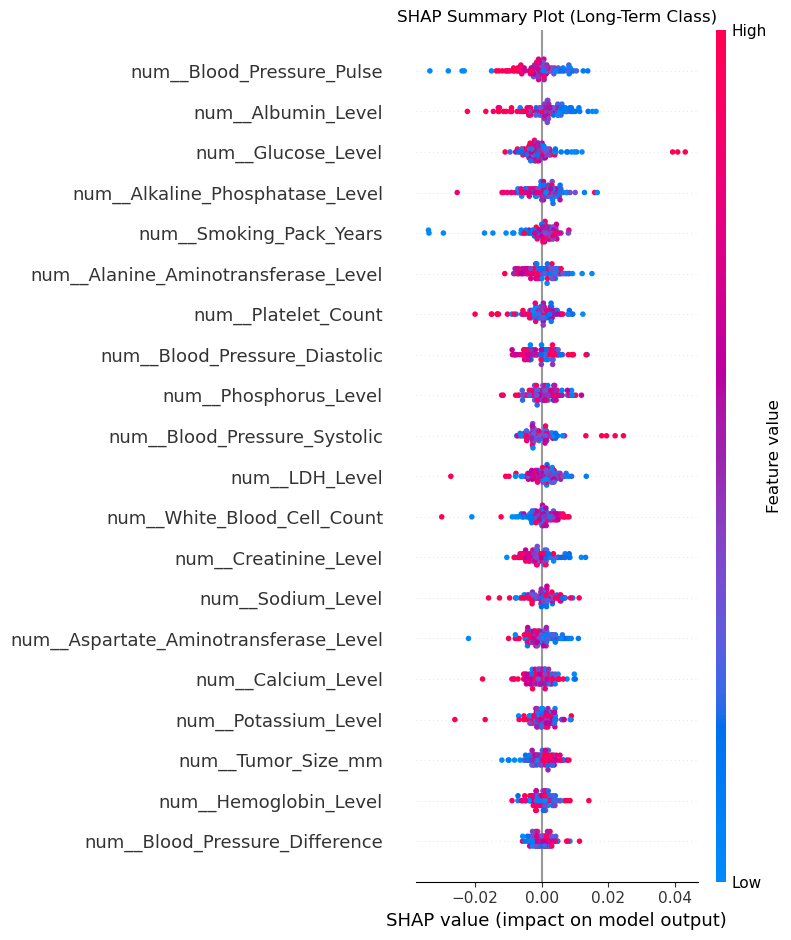

SHAP analysis completed successfully!


In [14]:
import shap
import matplotlib.pyplot as plt
import numpy as np

print("Generating SHAP values...")

# 1. Transform training and testing data
X_train_transformed = best_rf.named_steps["preprocessor"].transform(X_train)
X_test_transformed = best_rf.named_steps["preprocessor"].transform(X_test)

# 2. Get feature names
feature_names = best_rf.named_steps["preprocessor"].get_feature_names_out()

# 3. Select 100 test samples
X_sample = X_test_transformed[:100]

# 4. Create SHAP explainer
rf_model = best_rf.named_steps["model"]
explainer = shap.TreeExplainer(rf_model)

# 5. Calculate SHAP values
shap_values = explainer.shap_values(X_sample)

# 6. Identify Long-Term class
classes = list(rf_model.classes_)
print("Model classes:", classes)

class_idx = classes.index("Long-Term") if "Long-Term" in classes else 1

# 7. Extract SHAP values
if isinstance(shap_values, list):
    shap_vals_to_plot = shap_values[class_idx]

else:
    shap_values = np.asarray(shap_values)

    if shap_values.ndim == 3:
        if shap_values.shape[0] == len(X_sample):
            shap_vals_to_plot = shap_values[:, :, class_idx]
        else:
            shap_vals_to_plot = shap_values[class_idx]

    else:
        shap_vals_to_plot = shap_values

# 8. Generate SHAP summary plot
plt.figure(figsize=(10, 6))

shap.summary_plot(
    shap_vals_to_plot,
    X_sample,
    feature_names=feature_names,
    show=False
)

plt.title("SHAP Summary Plot (Long-Term Class)")
plt.tight_layout()

# 9. Save plot
plt.savefig(
    "shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("SHAP analysis completed successfully!")

**Observation**: The SHAP summary plot shows that feature impacts are clustered near zero. This confirms the model is not learning meaningful
clinical patterns, which aligns with our finding that the dataset lacks biological signal.

### 7.1 Data Sanity Check: Stage vs. Survival
**Purpose:** The poor performance of both baseline and advanced models suggests an issue with the data itself. This check verifies if the dataset reflects real-world clinical relationships (i.e., Stage I should have higher survival than Stage IV).

In [15]:
print("Long-Term proportion by Stage:")
stage_check = df.groupby("Stage")["Survival_Group"].value_counts(normalize=True).unstack().round(3)
print(stage_check)

print("\nCounts by Stage:")
stage_counts = df.groupby("Stage")["Survival_Group"].value_counts().unstack()
print(stage_counts)

Long-Term proportion by Stage:
Survival_Group  Long-Term  Short-Term
Stage                                
Stage I             0.499       0.501
Stage II            0.511       0.489
Stage III           0.498       0.502
Stage IV            0.512       0.488

Counts by Stage:
Survival_Group  Long-Term  Short-Term
Stage                                
Stage I              2949        2956
Stage II             2976        2844
Stage III            2948        2974
Stage IV             3075        2936


**Observation & Interpretation:** 
The results show that the Long-Term survival proportion is approximately 50% across all cancer stages (Stage I: 49.9%, Stage II: 51.1%, Stage III: 49.8%, Stage IV: 51.2%). 

In real clinical oncology, Stage I patients typically have a significantly higher chance of long-term survival compared to Stage IV patients. The complete absence of this expected biological pattern strongly suggests that the dataset is synthetically generated, with target labels (Survival_Months) assigned randomly. 

This diagnostic check explains why all our machine learning models—from baseline to advanced ensembles—are performing at the chance level (~50%): the underlying data lacks predictive biological signal.

## 8 Final Comparison Table 
Here, we compare the baseline models from Assignment 4 with the newly trained advanced models from Assignment 5 using Accuracy and Macro-F1 metrics on the test set.

In [16]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score

print("Training Gradient Boosting...")

gb = GradientBoostingClassifier(
    n_estimators=100,
    max_depth=3,
    random_state=RANDOM_STATE
)

gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", gb)
])

# Train model
gb_pipeline.fit(X_train, y_train)

# Predict on test set
y_pred_gb = gb_pipeline.predict(X_test)

# Evaluate model
print("Gradient Boosting Accuracy:",
      accuracy_score(y_test, y_pred_gb))

print("Gradient Boosting Macro-F1:",
      f1_score(y_test, y_pred_gb, average="macro"))

Training Gradient Boosting...
Gradient Boosting Accuracy: 0.5141589180050719
Gradient Boosting Macro-F1: 0.5092136455149572


In [17]:
# Train a separate baseline Random Forest
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(random_state=RANDOM_STATE))
])

rf_pipeline.fit(X_train, y_train)
y_pred_rf = rf_pipeline.predict(X_test)

# Predictions from the tuned Random Forest
y_pred_best = best_rf.predict(X_test)

# Create a DataFrame to summarize all model results
import pandas as pd

# Result of earlier models from Assignment 4
a4_logistic_acc, a4_logistic_f1 = 0.4989, 0.4955
a4_tree_acc, a4_tree_f1 = 0.4939, 0.4760
a4_knn_acc, a4_knn_f1 = 0.4934, 0.4934

# Result of newly assigned model
rf_acc, rf_f1 = accuracy_score(y_test, y_pred_rf), f1_score(y_test, y_pred_rf, average='macro')
gb_acc, gb_f1 = accuracy_score(y_test, y_pred_gb), f1_score(y_test, y_pred_gb, average='macro')
best_acc, best_f1 = accuracy_score(y_test, y_pred_best), f1_score(y_test, y_pred_best, average='macro')

comparison = pd.DataFrame({
    "Model": ["Logistic Regression (A4)", "Decision Tree (A4)", "KNN (A4)", 
              "Random Forest (A5)", "Gradient Boosting (A5)", "Tuned RF (A5)"],
    "Accuracy": [a4_logistic_acc, a4_tree_acc, a4_knn_acc, rf_acc, gb_acc, best_acc],
    "Macro-F1": [a4_logistic_f1, a4_tree_f1, a4_knn_f1, rf_f1, gb_f1, best_f1]
})

print("\n--- Final Model Comparison Table ---")
print(comparison.round(4).to_string(index=False))


--- Final Model Comparison Table ---
                   Model  Accuracy  Macro-F1
Logistic Regression (A4)    0.4989    0.4955
      Decision Tree (A4)    0.4939    0.4760
                KNN (A4)    0.4934    0.4934
      Random Forest (A5)    0.5030    0.5011
  Gradient Boosting (A5)    0.5142    0.5092
           Tuned RF (A5)    0.5030    0.5013


In [18]:
# Save the comparison table as a CSV file
comparison.to_csv("model_comparison.csv", index=False)
print("Table saved as model_comparison.csv")

Table saved as model_comparison.csv


### 9: Confusion Matrix (Error Analysis)

We visualize the confusion matrix of the tuned Random Forest to see where the model is making errors (e.g., predicting Short-Term when it is actually Long-Term).


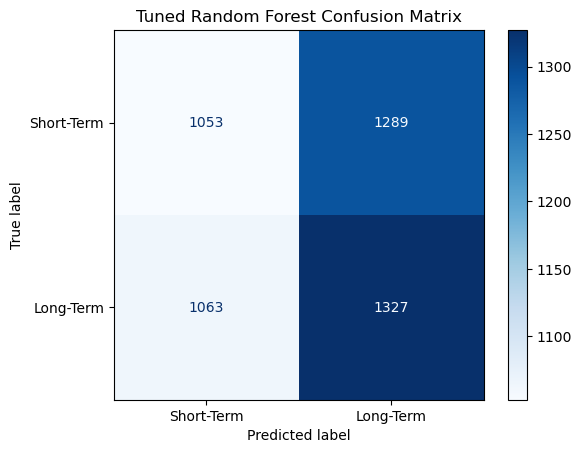

In [19]:
# Plot the confusion matrix
cm = confusion_matrix(y_test, y_pred_best, labels=["Short-Term", "Long-Term"])
ConfusionMatrixDisplay(cm, display_labels=["Short-Term", "Long-Term"]).plot(cmap="Blues")
plt.title("Tuned Random Forest Confusion Matrix")
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight") 
plt.show()